# Explore FIRMS data in R2 with DuckDB

Starter notebook. Run from any folder; it finds the repo root and `.env` itself.

Rules (see `CLAUDE.md`):
- Aggregate in DuckDB, never pull raw detections into pandas.
- Always filter silver on `source` and `year`.
- Fire counts: `is_vegetation_fire AND confidence_class <> 'low'`.
- Never sum counts across satellites.

## 1. Setup

In [1]:
import os
from pathlib import Path

import duckdb
from dotenv import load_dotenv

# Find repo root (folder containing .env or .git), then load credentials.
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
load_dotenv(root / ".env")

missing = [k for k in ("R2_KEY_ID", "R2_SECRET", "CF_ACCOUNT_ID") if not os.environ.get(k)]
assert not missing, f"Missing env vars: {missing}"

In [2]:
con = duckdb.connect()
con.sql("SET memory_limit = '3GB'")
con.sql("SET temp_directory = 'tmp_ml'")  # spill to disk instead of crashing; gitignored
con.sql(f"""
    CREATE SECRET r2 (
        TYPE r2,
        KEY_ID '{os.environ["R2_KEY_ID"]}',
        SECRET '{os.environ["R2_SECRET"]}',
        ACCOUNT_ID '{os.environ["CF_ACCOUNT_ID"]}'
    )
""")

BUCKET = "r2://firms-data"
SILVER = f"read_parquet('{BUCKET}/silver/detections/*/*/*.parquet', hive_partitioning = true)"
FIRE = "is_vegetation_fire AND confidence_class <> 'low'"

## 2. Small tables (cheap, start here)

In [3]:
con.sql(f"DESCRIBE SELECT * FROM '{BUCKET}/analysis/agg_monthly.parquet'")

column_nameVARCHAR,column_typeVARCHAR,nullVARCHAR,keyVARCHAR,defaultVARCHAR,extraVARCHAR
sensor,VARCHAR,YES,NULL,NULL,NULL
sat,VARCHAR,YES,NULL,NULL,NULL
country,VARCHAR,YES,NULL,NULL,NULL
yr,BIGINT,YES,NULL,NULL,NULL
mo,BIGINT,YES,NULL,NULL,NULL
type,BIGINT,YES,NULL,NULL,NULL
daynight,VARCHAR,YES,NULL,NULL,NULL
conf,VARCHAR,YES,NULL,NULL,NULL
n,BIGINT,YES,NULL,NULL,NULL
frp_sum,DOUBLE,YES,NULL,NULL,NULL


In [4]:
con.sql(f"SELECT * FROM '{BUCKET}/analysis/agg_monthly.parquet' LIMIT 10")

sensorVARCHAR,satVARCHAR,countryVARCHAR,yrBIGINT,moBIGINT,typeBIGINT,daynightVARCHAR,confVARCHAR,nBIGINT,frp_sumDOUBLE
MODIS,Terra,China,2000,11,0,D,nominal,1256,26818.99999999997
MODIS,Terra,Colombia,2000,12,0,D,low,14,179.49999999999997
MODIS,Terra,Cote_d_Ivoire,2000,12,0,D,nominal,4894,98092.19999999998
MODIS,Terra,Eritrea,2000,11,0,N,nominal,22,306.40000000000003
MODIS,Terra,Ghana,2000,11,0,D,nominal,1523,34055.900000000016
MODIS,Terra,Ghana,2000,12,0,D,high,2010,172199.0999999996
MODIS,Terra,Guinea,2000,11,0,D,nominal,1022,16646.999999999978
MODIS,Terra,Haiti,2000,12,0,D,nominal,5,146.70000000000002
MODIS,Terra,Honduras,2000,11,0,N,nominal,1,9.1
MODIS,Terra,Kenya,2000,12,0,N,high,1,28.9


## 3. Silver detections (filter `source` and `year`)

In [5]:
# Schema only: no data scanned.
con.sql(f"DESCRIBE SELECT * FROM {SILVER}")

column_nameVARCHAR,column_typeVARCHAR,nullVARCHAR,keyVARCHAR,defaultVARCHAR,extraVARCHAR
satellite,VARCHAR,YES,NULL,NULL,NULL
instrument,VARCHAR,YES,NULL,NULL,NULL
quality,VARCHAR,YES,NULL,NULL,NULL
acq_datetime_utc,TIMESTAMP,YES,NULL,NULL,NULL
acq_date_utc,DATE,YES,NULL,NULL,NULL
local_date,DATE,YES,NULL,NULL,NULL
latitude,DOUBLE,YES,NULL,NULL,NULL
longitude,DOUBLE,YES,NULL,NULL,NULL
lat10,INTEGER,YES,NULL,NULL,NULL
lon10,INTEGER,YES,NULL,NULL,NULL


In [6]:
# Example: monthly fire counts per satellite, one year. Counts stay per satellite, never summed.
monthly = con.sql(f"""
    SELECT satellite,
           month(local_date) AS month,
           count(*)          AS n,
           sum(frp)          AS frp_sum
    FROM {SILVER}
    WHERE source = 'modis' AND year = 2020 AND {FIRE}
    GROUP BY satellite, month
    ORDER BY satellite, month
""").df()  # small aggregate: safe for pandas
monthly.head()

,satellite,month,n,frp_sum
0,Aqua,1,243753,10009512.7
1,Aqua,2,219415,7967058.9
2,Aqua,3,217103,9560107.1
3,Aqua,4,180693,8003439.5
4,Aqua,5,130877,4318349.9


Matplotlib is building the font cache; this may take a moment.


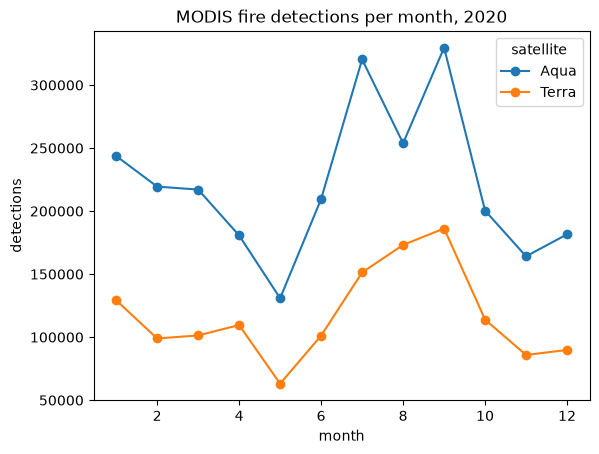

In [7]:
ax = monthly.pivot(index="month", columns="satellite", values="n").plot(
    marker="o", title="MODIS fire detections per month, 2020"
)
ax.set_ylabel("detections");

## 4. Your scratch space